# Surrogate training

This notebook trains the surrogate `SurrogateLSTM` from `surrogate/src/model.py` and evaluates it. The surrogate predicts the output voltage of the printed neuron: for every time step t it gets the input voltage vg1 up to and including t plus the condition (9 process and 21 mismatch parameters θ, VDD and temperature ω) and returns vout(t). The targets are the SPICE simulations from Cadence.

The surrogate is a recurrent network (LSTM). It walks through the curve step by step and keeps an internal state, similar to the charge on the membrane of the neuron. A first try with a transformer (26.11.) lost the rhythm under constant input after a few spikes and only predicted a flat average; a model with a state can keep it.

Steps:

1. **Setup and settings**: libraries, device (GPU/CPU), model size and training parameters in one place.
2. **Data**: `DatasetBuilder` reads the raw curves and splits them 70/20/10 by V/T group into training, validation and test.
3. **Training**: full training; the model with the lowest validation error is saved.
4. **Evaluation**: error on the test split, example curves, and the spikes: hits, missed and extra spikes, timing and height.

Requirements: a kernel with the packages from `VAT_SNN/requirements.txt` (torch, numpy, matplotlib). The notebook must run from its folder `surrogate/notebooks` so that the paths are right.

## 1. Setup and settings

In [12]:
# standard library: paths and timing
import sys
import time
from pathlib import Path

# arrays and plots
import numpy as np
import matplotlib.pyplot as plt
# tensors and layers
import torch
import torch.nn as nn

# folder surrogate/src with our code (the notebook runs in surrogate/notebooks)
SRC_DIR = Path.cwd().parent / "src"
# put it at the front of the import path so that "import model" finds our file
sys.path.insert(0, str(SRC_DIR))

# our own code: raw data → DataLoaders, and the model
from dataset_builder import DatasetBuilder
from model import SurrogateLSTM
from losses import van_rossum_loss
from metrics import compare_spikes

# train on the GPU if there is one, otherwise on the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# fixed seed: same start weights and same batch order on every run
torch.manual_seed(0)
# show which device is used
print("device:", device)

device: cuda


In [ ]:
# dataset folder inside surrogate/cadence/datasets
DATASET_NAME = "surrogate_ds_v1"
# time between two curve points after downsampling (DatasetBuilder default step=10 on the 1 µs grid)
DT = 10e-6

# size of the LSTM state per layer
HIDDEN_SIZE = 256
# number of stacked LSTM layers
N_LAYERS = 2
# share of values that dropout sets to zero between the LSTM layers during training (against overfitting)
DROPOUT = 0.2

# loss: time constant of the van Rossum kernel in time steps (3 × 10 µs = 30 µs)
TAU_STEPS = 3
# loss: weight of the plain MSE next to the van Rossum distance (keeps the spikes sharp)
MSE_WEIGHT = 0.1

# spike comparison: largest distance between the starts of a SPICE and a surrogate spike to count as a pair (3 × 10 µs = 30 µs)
TOLERANCE_STEPS = 3

# curves per mini-batch
BATCH_SIZE = 64
# start learning rate of AdamW
LEARNING_RATE = 1e-3
# the learning rate is multiplied by this factor when the validation error stops improving
LR_FACTOR = 0.5
# number of epochs without improvement before the learning rate is lowered
LR_PATIENCE = 5
# weight decay of AdamW (pulls the weights slightly towards 0)
WEIGHT_DECAY = 0.01
# upper limit for the number of passes over the training split (early stopping usually ends earlier)
N_EPOCHS = 1000
# early stopping: stop when the validation error has not improved for this many epochs
PATIENCE = 20

# file for the model with the lowest validation error
CHECKPOINT_PATH = Path.cwd().parent / "checkpoints" / "surrogate_lstm.pt"

## 2. Data

`DatasetBuilder` reads `ds_all_raw.npz`, takes every 10th point of the 1 µs grid and cuts the curves to 500 points (5 ms). The split is made by V/T group: all curves of a group share the same combination of VDD and temperature and end up in the same split. Validation and test therefore check whether the surrogate is also right at V/T values it has not seen during training.

`build_loaders` wraps every split into a `DataLoader`. It delivers mini-batches of six tensors: the five model inputs and, last, the target curve vout. Only the training loader shuffles the curves.

In [14]:
# read the raw curves, split them 70/20/10 by V/T group and wrap every split into a DataLoader
loaders = DatasetBuilder(DATASET_NAME).build_loaders(BATCH_SIZE)
# the three loaders under short names
train_loader, validation_loader, test_loader = loaders.train_loader, loaders.validation_loader, loaders.test_loader

# print the number of curves per split
for name, loader in [("training", train_loader), ("validation", validation_loader), ("test", test_loader)]:
    # every loader holds its SurrogateDataset in loader.dataset
    print(f"{name}: {len(loader.dataset)} curves")

training: 11340 curves
validation: 3240 curves
test: 1620 curves


## 3. Training

Now the full training with a fresh model:

- **Loss**: the van Rossum distance plus a small share of plain MSE (`van_rossum_loss` in `surrogate/src/losses.py`). Before comparing, both curves are smoothed with a causal exponential kernel with time constant `TAU_STEPS`. A spike that is a step or two late still overlaps with the true one after smoothing and costs little, while a missing or extra spike costs a whole smoothed spike. With plain MSE, a spike that is 3 steps late costs even more than a missing spike. The MSE share with weight `MSE_WEIGHT` keeps the spikes sharp and high.

- **AdamW** is Adam with weight decay, a common default optimizer.
- **Learning rate**: it starts at `LEARNING_RATE`. Whenever the validation loss has not improved for `LR_PATIENCE` epochs, it is multiplied by `LR_FACTOR` (halved). The model takes big steps at the start and finer ones as soon as it begins to jump around the minimum. `PATIENCE` is larger than `LR_PATIENCE`, so that the learning rate can be lowered a few times before early stopping ends the training.
- **After every epoch** we measure the loss on the validation split. The model with the lowest validation loss so far is saved in `surrogate/checkpoints/`, together with its size, so that it can be rebuilt exactly later (e.g. in the P-SNN).
- **Early stopping**: if the validation loss has not improved for `PATIENCE` epochs in a row, the training stops early. From then on the model would only learn the training curves by heart.

If the validation error is clearly above the training error, the model learns the training curves by heart instead of understanding the neuron (overfitting).

`train_epoch` runs one training pass over the training split. `evaluate` then measures a split with dropout off and fixed weights, for the training split as well, so that training and validation values are comparable. It returns the loss, the MSE (for the RMSE printouts) and, as extra information, the spike comparison from `compare_spikes` in `surrogate/src/metrics.py`: a spike starts where vout rises above VDD/2, and every SPICE spike is paired with at most one surrogate spike that starts at most `TOLERANCE_STEPS` steps away. Spikes without a partner count as missed (SPICE) or extra (surrogate). The F1 score 2 · pairs / (SPICE spikes + surrogate spikes) sums this up: 1 if every spike has a partner, 0 if none has. Unlike a plain spike count, a missed and an extra spike do not cancel out, and a spike far off counts as wrong. The error is the mean squared error (MSE) in V². Most outputs show its square root (RMSE) in mV, because that reads as a typical deviation of the voltage.

In [30]:
def train_epoch(model, loader, optimizer):
    """One training pass over the loader: dropout on, the weights change after every mini-batch."""
    # training mode switches dropout on
    model.train()
    # one mini-batch at a time
    for batch in loader:
        # move the five inputs and the target to the device
        *inputs, target = [tensor.to(device) for tensor in batch]
        # predicted output voltage, shape (b, 500)
        prediction = model(*inputs)
        # van Rossum distance plus a small share of MSE, the quantity the training minimises
        loss = van_rossum_loss(prediction, target, TAU_STEPS, MSE_WEIGHT)
        # delete the gradients of the previous step
        optimizer.zero_grad()
        # compute the gradients of this batch
        loss.backward()
        # cap the gradient length at 1, keeps LSTM training stable (gradients can explode over 500 steps)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        # move the weights one step against the gradient
        optimizer.step()


def evaluate(model, loader):
    """Measures the model on all curves of the loader, with dropout off and fixed weights.
    Returns the mean loss in V², the mean MSE in V² and the SpikeComparison of all curves."""
    # eval mode switches dropout off
    model.eval()
    # predictions, targets and VDD of all mini-batches, on the CPU
    predictions, targets, vdds = [], [], []
    # no gradients needed for measuring
    with torch.no_grad():
        # one mini-batch at a time
        for batch in loader:
            # move the five inputs and the target to the device
            *inputs, target = [tensor.to(device) for tensor in batch]
            # predicted output voltage, shape (b, 500)
            predictions.append(model(*inputs).cpu())
            # SPICE output voltage
            targets.append(target.cpu())
            # VDD of every curve (fourth model input), needed for the spike threshold
            vdds.append(inputs[3].cpu())
    # join all mini-batches
    prediction, target, vdd = torch.cat(predictions), torch.cat(targets), torch.cat(vdds)
    # van Rossum loss and plain MSE over all time steps and curves
    loss = van_rossum_loss(prediction, target, TAU_STEPS, MSE_WEIGHT).item()
    mse = nn.functional.mse_loss(prediction, target).item()
    # pair the spikes of surrogate and SPICE
    spikes = compare_spikes(prediction.numpy(), target.numpy(), vdd.numpy(), TOLERANCE_STEPS)
    # loss, MSE and spike comparison of the whole split
    return loss, mse, spikes

In [31]:
# model size, saved together with the weights so the model can be rebuilt later
model_config = dict(hidden_size=HIDDEN_SIZE, n_layers=N_LAYERS, dropout=DROPOUT)
# fresh model with the settings from above
model = SurrogateLSTM(**model_config).to(device)
# number of learnable values
print("learnable parameters:", sum(parameter.numel() for parameter in model.parameters()))
# AdamW: Adam with weight decay
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# lower the learning rate by LR_FACTOR when the validation loss has not improved for LR_PATIENCE epochs
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE)
# MSE and spike F1 score per epoch, for the plot below
history = {"train": [], "validation": [], "train_f1": [], "validation_f1": []}
# lowest validation loss so far
best_validation_loss = float("inf")
# epochs in a row without a new best validation loss
epochs_without_improvement = 0
# create the checkpoint folder if it does not exist yet
CHECKPOINT_PATH.parent.mkdir(exist_ok=True)

# one epoch = one pass over the training split
for epoch in range(1, N_EPOCHS + 1):
    # start time, to print the duration of the epoch
    start = time.time()
    # train one pass
    train_epoch(model, train_loader, optimizer)
    # measure on the training split with dropout off (the training loss is not needed)
    _, train_mse, train_spikes = evaluate(model, train_loader)
    # measure on the validation split
    validation_loss, validation_mse, validation_spikes = evaluate(model, validation_loader)
    # learning rate used in this epoch (for the printout below)
    learning_rate = optimizer.param_groups[0]["lr"]
    # let the scheduler see the validation loss (a smooth signal), it lowers the learning rate if needed
    scheduler.step(validation_loss)
    # remember both errors and both F1 scores
    history["train"].append(train_mse)
    history["validation"].append(validation_mse)
    history["train_f1"].append(train_spikes.f1)
    history["validation_f1"].append(validation_spikes.f1)
    # better than all epochs before?
    if validation_loss < best_validation_loss:
        # remember the new best value
        best_validation_loss = validation_loss
        # save weights, model size, epoch and the validation loss
        torch.save({"model": model.state_dict(), "config": model_config, "epoch": epoch, "validation_loss": validation_loss}, CHECKPOINT_PATH)
        # improvement, so the count starts again
        epochs_without_improvement = 0
    # no improvement in this epoch
    else:
        # one more epoch without improvement
        epochs_without_improvement += 1
    # print both errors as RMSE in mV, both spike F1 scores, the validation loss, the learning rate and the duration
    print(f"epoch {epoch:2d}: training {np.sqrt(train_mse) * 1000:5.1f} mV, F1 {train_spikes.f1:.3f} | validation {np.sqrt(validation_mse) * 1000:5.1f} mV, F1 {validation_spikes.f1:.3f}, loss {validation_loss:.4f} | lr {learning_rate:.1e} | {time.time() - start:.0f} s")
    # stop when the validation loss has not improved for PATIENCE epochs
    if epochs_without_improvement >= PATIENCE:
        # say why the training ends here
        print(f"early stopping: no improvement for {PATIENCE} epochs, best epoch {epoch - PATIENCE}")
        # leave the epoch loop
        break

learnable parameters: 824577


KeyboardInterrupt: 

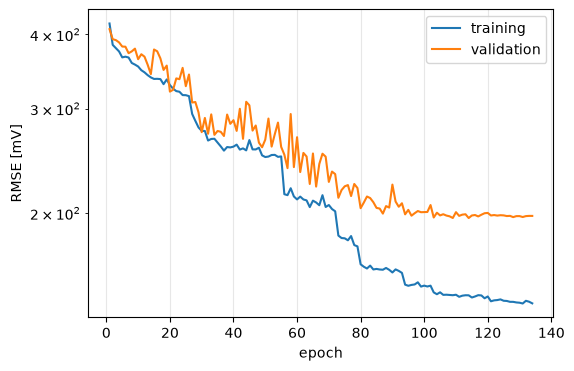

In [17]:
# epochs 1 … N for the x axis
epochs = np.arange(1, len(history["train"]) + 1)
# two plots side by side: error on the left, spike F1 score on the right
fig, (ax_error, ax_spikes) = plt.subplots(1, 2, figsize=(12, 4))
# training and validation error as RMSE in mV
ax_error.plot(epochs, np.sqrt(history["train"]) * 1000, label="training")
ax_error.plot(epochs, np.sqrt(history["validation"]) * 1000, label="validation")
# logarithmic y axis, the error falls over orders of magnitude
ax_error.set_yscale("log")
# axis labels, legend and light grid
ax_error.set_xlabel("epoch")
ax_error.set_ylabel("RMSE [mV]")
ax_error.legend()
ax_error.grid(alpha=0.3)
# spike F1 score of training and validation
ax_spikes.plot(epochs, history["train_f1"], label="training")
ax_spikes.plot(epochs, history["validation_f1"], label="validation")
# axis labels, legend and light grid
ax_spikes.set_xlabel("epoch")
ax_spikes.set_ylabel("spike F1 score")
ax_spikes.legend()
ax_spikes.grid(alpha=0.3)
# avoid overlapping labels
plt.tight_layout()
# show the plot
plt.show()

## 4. Evaluation on the test split

For the evaluation we load the saved best model and predict all test curves. The test groups have V/T combinations that occurred neither in training nor in validation.

We look at three things:

1. **Voltage error**: RMSE over all test curves, plus median and maximum per curve.
2. **Example curves**: the best, a median and the worst test curve compared with SPICE.
3. **Spikes**: for the P-SNN what matters in the end is whether the neuron fires at the right time. As during training, `compare_spikes` pairs every SPICE spike with at most one surrogate spike that starts at most `TOLERANCE_STEPS` steps away. We count the pairs (hits), the missed and the extra spikes. For the hits we also look at the timing (start of the surrogate spike minus start of the SPICE spike) and at the height (peak of the surrogate spike minus peak of the SPICE spike).

In [ ]:
# load the weights of the epoch with the lowest validation error
checkpoint = torch.load(CHECKPOINT_PATH)
# rebuild the model with the saved size and load the weights
model = SurrogateLSTM(**checkpoint["config"]).to(device)
model.load_state_dict(checkpoint["model"])
# eval mode: dropout off
model.eval()
# show which epoch was the best
print("best model from epoch", checkpoint["epoch"])

# no gradients needed for the evaluation
with torch.no_grad():
    # predict every test batch, move it back to the CPU and join all batches
    test_prediction = torch.cat([model(*[tensor.to(device) for tensor in batch[:5]]).cpu() for batch in test_loader]).numpy()

# test split (the SurrogateDataset behind the test loader) as numpy arrays
test = test_loader.dataset
test_input = test.input_voltage.numpy()
test_target = test.output_voltage.numpy()
test_vdd = test.vdd.numpy()
test_temperature = test.temperature.numpy()

# squared error of every value
squared_error = (test_prediction - test_target) ** 2
# RMSE of every curve
rmse_per_curve = np.sqrt(squared_error.mean(axis=1))
# RMSE over all test values
print(f"test RMSE overall: {np.sqrt(squared_error.mean()) * 1000:.1f} mV")
# typical and worst curve
print(f"per curve: median {np.median(rmse_per_curve) * 1000:.1f} mV | worst {rmse_per_curve.max() * 1000:.1f} mV")

In [ ]:
# curves sorted from the smallest to the largest error
order = np.argsort(rmse_per_curve)
# best, median and worst test curve
examples = {"best": order[0], "median": order[len(order) // 2], "worst": order[-1]}
# time axis in ms
time_ms = np.arange(test_target.shape[1]) * DT * 1000

# one row per example curve, shared time axis
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
# draw every example into its own row
for ax, (label, i) in zip(axes, examples.items()):
    # input voltage in grey in the background
    ax.plot(time_ms, test_input[i], color="grey", alpha=0.5, label="vg1 (input)")
    # SPICE output and surrogate output
    ax.plot(time_ms, test_target[i], label="vout SPICE")
    ax.plot(time_ms, test_prediction[i], "--", label="vout surrogate")
    # title with error and operating point of this curve
    ax.set_title(f"{label} curve: RMSE {rmse_per_curve[i] * 1000:.1f} mV | VDD {test_vdd[i]:.3f} V | T {test_temperature[i]:.1f} °C")
    # y axis label
    ax.set_ylabel("voltage [V]")
# legend only once
axes[0].legend(loc="upper right")
# x axis label only at the bottom
axes[-1].set_xlabel("time [ms]")
# avoid overlapping titles
plt.tight_layout()
# show the plot
plt.show()

In [ ]:
# pair the spikes of surrogate and SPICE in all test curves
test_spikes = compare_spikes(test_prediction, test_target, test_vdd, TOLERANCE_STEPS)
# timing error of every hit in µs (positive: surrogate too late)
timing_error = test_spikes.timing_error * DT * 1e6
# peak error of every hit in mV (negative: surrogate too low)
peak_error = test_spikes.peak_error * 1000

# number of spikes on both sides
print(f"spikes: SPICE {test_spikes.n_true} | surrogate {test_spikes.n_predicted}")
# hits, missed and extra spikes, each also as share of the SPICE spikes
print(f"hits (at most {TOLERANCE_STEPS * DT * 1e6:.0f} µs apart): {test_spikes.n_hits} ({test_spikes.n_hits / test_spikes.n_true * 100:.1f} %) | "
      f"missed: {test_spikes.n_missed} ({test_spikes.n_missed / test_spikes.n_true * 100:.1f} %) | "
      f"extra: {test_spikes.n_extra} ({test_spikes.n_extra / test_spikes.n_true * 100:.1f} %) of the SPICE spikes")
# spike F1 score
print(f"spike F1 score: {test_spikes.f1:.3f}")
# timing and height, only if there are hits at all
if test_spikes.n_hits > 0:
    # typical and large timing error, and the mean shift (shows a constant delay)
    print(f"timing of the hits: median |Δt| {np.median(np.abs(timing_error)):.0f} µs | 95th percentile {np.percentile(np.abs(timing_error), 95):.0f} µs | "
          f"mean shift {timing_error.mean():+.1f} µs (time grid {DT * 1e6:.0f} µs)")
    # typical and large height error, and the mean shift (negative: spikes too low)
    print(f"peak height of the hits: median |Δ| {np.median(np.abs(peak_error)):.0f} mV | 95th percentile {np.percentile(np.abs(peak_error), 95):.0f} mV | "
          f"mean shift {peak_error.mean():+.0f} mV")